# Churn rate analysis by Contract

This analysis preserves the original `Churn` column, creates a numeric `Churn_Encoded` column, and compares customer volume and churn rate across contract types. The table and charts below are generated directly from the loaded dataset; interpretations should be based on the displayed results.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd
import seaborn as sns

notebook_dir = Path.cwd()
if notebook_dir.name != "notebooks":
    notebook_dir = notebook_dir / "notebooks"
dataset_path = notebook_dir.parent / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(dataset_path)
df["Churn_Encoded"] = df["Churn"].map({"Yes": 1, "No": 0})

print(f"Dataset: {dataset_path}")
print(f"Original Churn column preserved: {'Churn' in df.columns}")
display(df[["Churn", "Churn_Encoded"]].head())

Dataset: d:\customer-churn-prediction\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv
Original Churn column preserved: True


,Churn,Churn_Encoded
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


In [3]:
encoded_missing_count = df["Churn_Encoded"].isna().sum()
invalid_encoded_values = sorted(
    set(df["Churn_Encoded"].dropna().unique()) - {0, 1}
)

original_counts = df["Churn"].value_counts(dropna=False)
encoded_counts = df["Churn_Encoded"].value_counts(dropna=False)
encoding_counts_check = pd.DataFrame(
    {
        "Original Churn": [original_counts.get("No", 0), original_counts.get("Yes", 0)],
        "Encoded Churn": [encoded_counts.get(0, 0), encoded_counts.get(1, 0)],
    },
    index=["No / 0", "Yes / 1"],
)
encoding_counts_check["Match"] = (
    encoding_counts_check["Original Churn"]
    == encoding_counts_check["Encoded Churn"]
)

print(f"NaN trong Churn_Encoded: {encoded_missing_count}")
print(f"Giá trị ngoài 0 và 1: {invalid_encoded_values}")
display(encoding_counts_check)


NaN trong Churn_Encoded: 0
Giá trị ngoài 0 và 1: []


,Original Churn,Encoded Churn,Match
No / 0,5174,5174,True
Yes / 1,1869,1869,True


In [4]:
contract_summary = (
    df.groupby("Contract")
    .agg(
        **{
            "Total customers": ("Churn_Encoded", "size"),
            "Churn count": ("Churn_Encoded", "sum"),
            "Churn rate (%)": ("Churn_Encoded", "mean"),
        }
    )
    .assign(**{"Churn rate (%)": lambda data: data["Churn rate (%)"] * 100})
    .sort_values("Churn rate (%)", ascending=False)
    .reset_index()
)

total_customers_table = contract_summary[["Contract", "Total customers"]]
churn_count_table = contract_summary[["Contract", "Churn count"]]
churn_rate_table = contract_summary[["Contract", "Churn rate (%)"]].copy()
churn_rate_table["Churn rate (%)"] = churn_rate_table["Churn rate (%)"].map(
    lambda rate: f"{rate:.2f}%"
)

print("1. Total Customers")
display(total_customers_table)
print("2. Churn Count")
display(churn_count_table)
print("3. Churn Rate (%)")
display(churn_rate_table)

1. Total Customers


,Contract,Total customers
0,Month-to-month,3875
1,One year,1473
2,Two year,1695


2. Churn Count


,Contract,Churn count
0,Month-to-month,1655
1,One year,166
2,Two year,48


3. Churn Rate (%)


,Contract,Churn rate (%)
0,Month-to-month,42.71%
1,One year,11.27%
2,Two year,2.83%


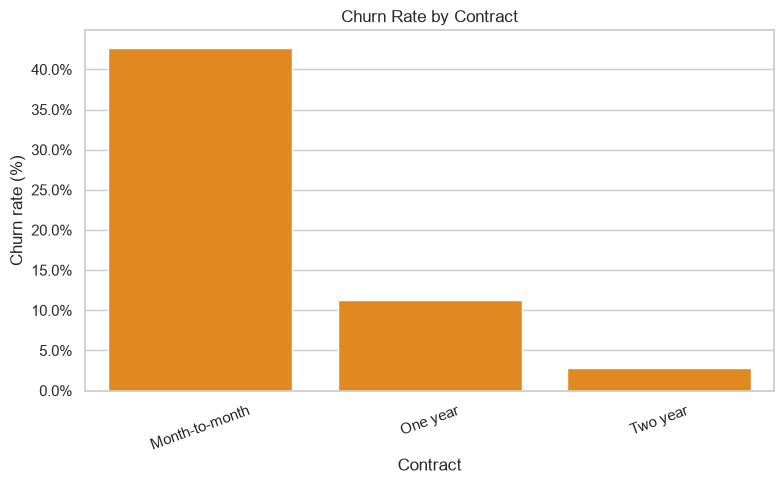

In [5]:
sns.set_theme(style="whitegrid")
contract_order = contract_summary["Contract"].tolist()

plt.figure(figsize=(8, 5))
sns.barplot(
    data=contract_summary,
    x="Contract",
    y="Churn rate (%)",
    order=contract_order,
    color="darkorange",
)
plt.title("Churn Rate by Contract")
plt.xlabel("Contract")
plt.ylabel("Churn rate (%)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=100))
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

## Churn Rate by Contract and Tenure

The following analysis groups customers by tenure and contract. It reports churn rates together with customer counts for every combination, so rates can be interpreted alongside their sample sizes. The results describe observed patterns only and do not establish causal relationships.

In [6]:
tenure_analysis = df.copy()
tenure_labels = [
    "0?12 months",
    "13?24 months",
    "25?48 months",
    "49?72 months",
]
tenure_analysis["tenure_group"] = pd.cut(
    tenure_analysis["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=tenure_labels,
    include_lowest=True,
)
tenure_analysis["tenure_group"] = tenure_analysis["tenure_group"].cat.reorder_categories(
    tenure_labels,
    ordered=True,
)

tenure_contract_summary = (
    tenure_analysis.groupby(["tenure_group", "Contract"], observed=False)
    .agg(
        **{
            "Customer count": ("Churn_Encoded", "size"),
            "Churn Rate (%)": ("Churn_Encoded", "mean"),
        }
    )
    .assign(**{"Churn Rate (%)": lambda data: data["Churn Rate (%)"] * 100})
    .reset_index()
)

churn_rate_pivot = tenure_contract_summary.pivot(
    index="tenure_group",
    columns="Contract",
    values="Churn Rate (%)",
).reindex(tenure_labels)

customer_count_pivot = tenure_contract_summary.pivot(
    index="tenure_group",
    columns="Contract",
    values="Customer count",
).reindex(tenure_labels)

print("Churn Rate (%) by Contract and Tenure")
display_churn_rate_pivot = churn_rate_pivot.map(
    lambda rate: f"{rate:.2f}%" if pd.notna(rate) else "NaN"
)
display(display_churn_rate_pivot)

print("Customer counts by Contract and Tenure")
display(customer_count_pivot.astype("Int64"))

Churn Rate (%) by Contract and Tenure


Contract,Month-to-month,One year,Two year
tenure_group,,,
0?12 months,51.35%,10.48%,0.00%
13?24 months,37.72%,8.12%,0.00%
25?48 months,32.92%,10.62%,2.19%
49?72 months,26.02%,12.93%,3.33%


Customer counts by Contract and Tenure


Contract,Month-to-month,One year,Two year
tenure_group,,,
0?12 months,1994,124,68
13?24 months,737,197,90
25?48 months,802,518,274
49?72 months,342,634,1263


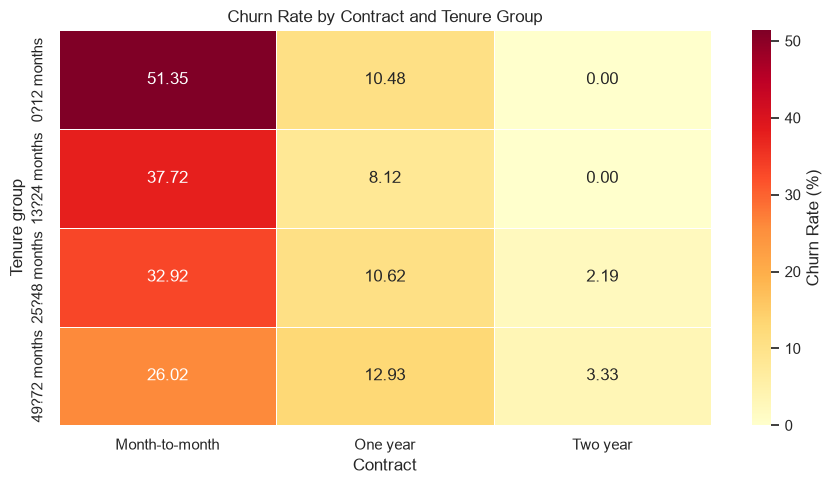

In [7]:
plt.figure(figsize=(9, 5))
sns.heatmap(
    churn_rate_pivot,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Churn Rate (%)"},
)
plt.title("Churn Rate by Contract and Tenure Group")
plt.xlabel("Contract")
plt.ylabel("Tenure group")
plt.tight_layout()
plt.show()

## MonthlyCharges distribution by Churn

This section compares the observed `MonthlyCharges` distributions for `Churn = 1` and `Churn = 0`. It reports descriptive statistics and visualizes the distributions without making causal claims.

In [8]:
monthly_charges_analysis = df[["MonthlyCharges", "Churn", "Churn_Encoded"]].copy()
monthly_charges_analysis = monthly_charges_analysis.dropna(subset=["MonthlyCharges", "Churn_Encoded"])

monthly_charges_stats = (
    monthly_charges_analysis.groupby("Churn_Encoded")["MonthlyCharges"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        q1=lambda values: values.quantile(0.25),
        q3=lambda values: values.quantile(0.75),
    )
    .rename(index={0: "Churn = 0", 1: "Churn = 1"})
)

print("MonthlyCharges descriptive statistics by Churn")
display(monthly_charges_stats.round(2))

mean_difference = monthly_charges_stats.loc["Churn = 1", "mean"] - monthly_charges_stats.loc["Churn = 0", "mean"]
median_difference = monthly_charges_stats.loc["Churn = 1", "median"] - monthly_charges_stats.loc["Churn = 0", "median"]
print(f"Observed mean difference (Churn = 1 minus Churn = 0): {mean_difference:.2f}")
print(f"Observed median difference (Churn = 1 minus Churn = 0): {median_difference:.2f}")
print("These are descriptive differences in this dataset and do not establish causation.")

MonthlyCharges descriptive statistics by Churn


,count,mean,median,std,q1,q3
Churn_Encoded,,,,,,
Churn = 0,5174,61.27,64.43,31.09,25.10,88.4
Churn = 1,1869,74.44,79.65,24.67,56.15,94.2


Observed mean difference (Churn = 1 minus Churn = 0): 13.18
Observed median difference (Churn = 1 minus Churn = 0): 15.22
These are descriptive differences in this dataset and do not establish causation.


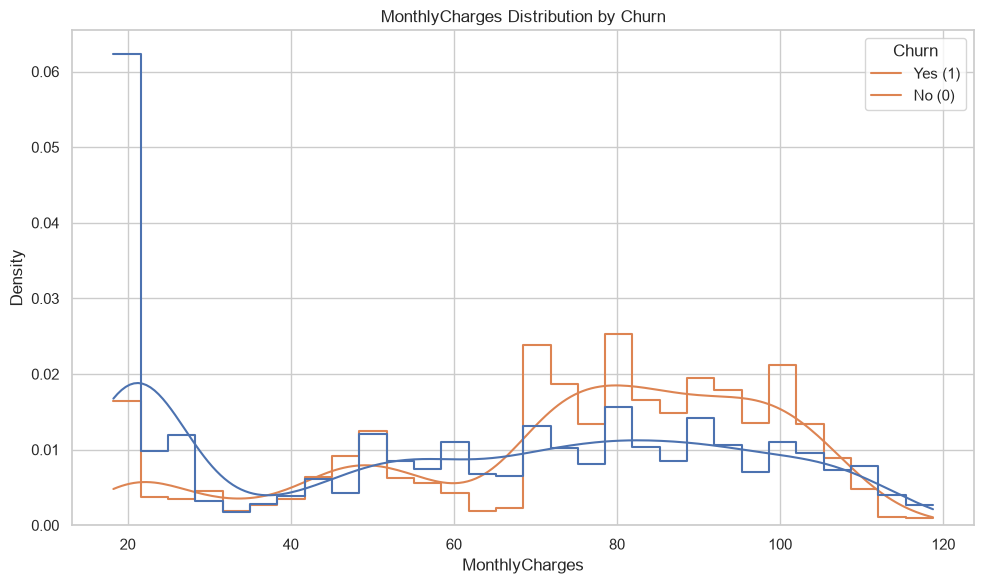

In [9]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(
    data=monthly_charges_analysis,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    kde=True,
)
plt.title("MonthlyCharges Distribution by Churn")
plt.xlabel("MonthlyCharges")
plt.ylabel("Density")
plt.legend(title="Churn", labels=["Yes (1)", "No (0)"])
plt.tight_layout()
plt.show()

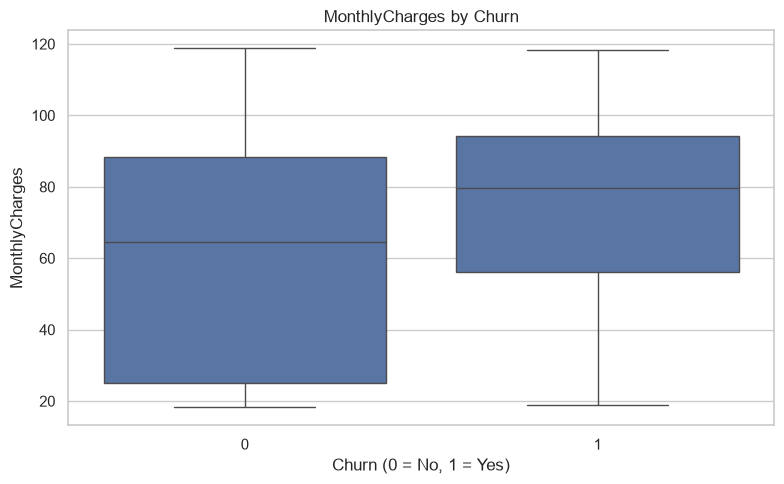

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=monthly_charges_analysis,
    x="Churn_Encoded",
    y="MonthlyCharges",
    order=[0, 1],
)
plt.title("MonthlyCharges by Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("MonthlyCharges")
plt.tight_layout()
plt.show()

## Churn Rate by Contract and Total Services

This section counts subscribed services per customer, groups the counts, and compares churn across Contract and TotalServices groups.

In [11]:
service_columns = [
    "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity",
    "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
    "StreamingMovies",
]
analysis_df = df.copy()
service_flags = pd.DataFrame(index=analysis_df.index)
service_flags["PhoneService"] = analysis_df["PhoneService"].eq("Yes")
service_flags["MultipleLines"] = analysis_df["MultipleLines"].eq("Yes")
service_flags["InternetService"] = analysis_df["InternetService"].ne("No")
for service in service_columns[3:]:
    service_flags[service] = analysis_df[service].eq("Yes")
analysis_df["TotalServices"] = service_flags.sum(axis=1)
analysis_df["TotalServicesGroup"] = pd.cut(
    analysis_df["TotalServices"], bins=[-1, 2, 5, 7, 9],
    labels=["0-2 services", "3-5 services", "6-7 services", "8-9 services"],
)
analysis_df["Churn_Encoded"] = analysis_df["Churn"].map({"Yes": 1, "No": 0})
contract_service_summary = (
    analysis_df.groupby(["Contract", "TotalServicesGroup"], observed=False)
    .agg(
        **{
            "Customer count": ("Churn_Encoded", "size"),
            "Churn count": ("Churn_Encoded", "sum"),
            "Churn rate (%)": ("Churn_Encoded", "mean"),
        }
    )
    .assign(**{"Churn rate (%)": lambda data: data["Churn rate (%)"] * 100})
    .reset_index()
)
display_table = contract_service_summary.copy()
display_table["Churn rate (%)"] = display_table["Churn rate (%)"].map(lambda rate: f"{rate:.2f}%")
display(display_table)


,Contract,TotalServicesGroup,Customer count,Churn count,Churn rate (%)
0,Month-to-month,0-2 services,1092,388,35.53%
1,Month-to-month,3-5 services,2085,966,46.33%
2,Month-to-month,6-7 services,630,284,45.08%
3,Month-to-month,8-9 services,68,17,25.00%
4,One year,0-2 services,388,11,2.84%
5,One year,3-5 services,448,47,10.49%
6,One year,6-7 services,506,82,16.21%
7,One year,8-9 services,131,26,19.85%
8,Two year,0-2 services,643,5,0.78%
9,Two year,3-5 services,200,8,4.00%


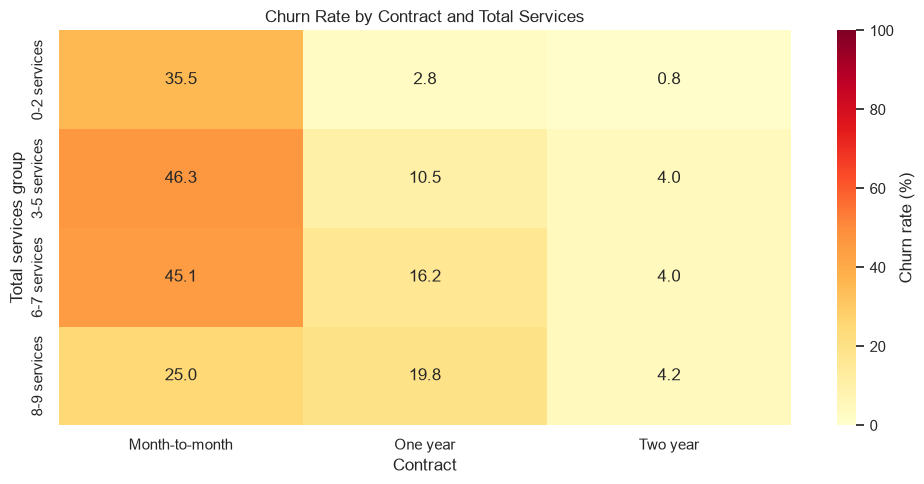

In [12]:
churn_rate_heatmap = contract_service_summary.pivot(
    index="TotalServicesGroup", columns="Contract", values="Churn rate (%)"
).reindex(
    index=["0-2 services", "3-5 services", "6-7 services", "8-9 services"],
    columns=["Month-to-month", "One year", "Two year"],
)
plt.figure(figsize=(10, 5))
sns.heatmap(churn_rate_heatmap, annot=True, fmt=".1f", cmap="YlOrRd", vmin=0, vmax=100,
            cbar_kws={"label": "Churn rate (%)"})
plt.title("Churn Rate by Contract and Total Services")
plt.xlabel("Contract")
plt.ylabel("Total services group")
plt.tight_layout()
plt.show()

## Tenure by Contract and Total Services

This section compares customer count, median tenure, and the previously calculated churn rate for each Contract x TotalServicesGroup.

In [15]:
small_sample_threshold = 30

churn_tenure_summary = (
    analysis_df.groupby(
        ["Contract", "TotalServicesGroup", "Churn"], observed=False
    )
    .agg(
        **{
            "Customer count": ("customerID", "size"),
            "Median tenure (months)": ("tenure", "median"),
        }
    )
    .reset_index()
)
churn_tenure_summary["Small sample"] = churn_tenure_summary["Customer count"] < small_sample_threshold

churn_tenure_comparison = churn_tenure_summary.merge(
    contract_service_summary[["Contract", "TotalServicesGroup", "Churn rate (%)"]],
    on=["Contract", "TotalServicesGroup"],
    how="left",
    validate="many_to_one",
).sort_values(["Contract", "TotalServicesGroup", "Churn"])

print(f"Small-sample threshold: n < {small_sample_threshold}")
display(churn_tenure_comparison)
print("Groups flagged as small samples:")
display(churn_tenure_comparison[churn_tenure_comparison["Small sample"]])


Small-sample threshold: n < 30


,Contract,TotalServicesGroup,Churn,Customer count,Median tenure (months),Small sample,Churn rate (%)
0,Month-to-month,0-2 services,No,704,6.0,False,35.531136
1,Month-to-month,0-2 services,Yes,388,1.0,False,35.531136
2,Month-to-month,3-5 services,No,1119,18.0,False,46.330935
3,Month-to-month,3-5 services,Yes,966,8.0,False,46.330935
4,Month-to-month,6-7 services,No,346,34.5,False,45.079365
5,Month-to-month,6-7 services,Yes,284,24.5,False,45.079365
6,Month-to-month,8-9 services,No,51,50.0,False,25.000000
7,Month-to-month,8-9 services,Yes,17,41.0,True,25.000000
8,One year,0-2 services,No,377,26.0,False,2.835052
9,One year,0-2 services,Yes,11,18.0,True,2.835052


Groups flagged as small samples:


,Contract,TotalServicesGroup,Churn,Customer count,Median tenure (months),Small sample,Churn rate (%)
7,Month-to-month,8-9 services,Yes,17,41.0,True,25.000000
9,One year,0-2 services,Yes,11,18.0,True,2.835052
15,One year,8-9 services,Yes,26,58.5,True,19.847328
17,Two year,0-2 services,Yes,5,53.0,True,0.777605
19,Two year,3-5 services,Yes,8,60.5,True,4.000000
21,Two year,6-7 services,Yes,18,66.5,True,4.017857
23,Two year,8-9 services,Yes,17,67.0,True,4.207921


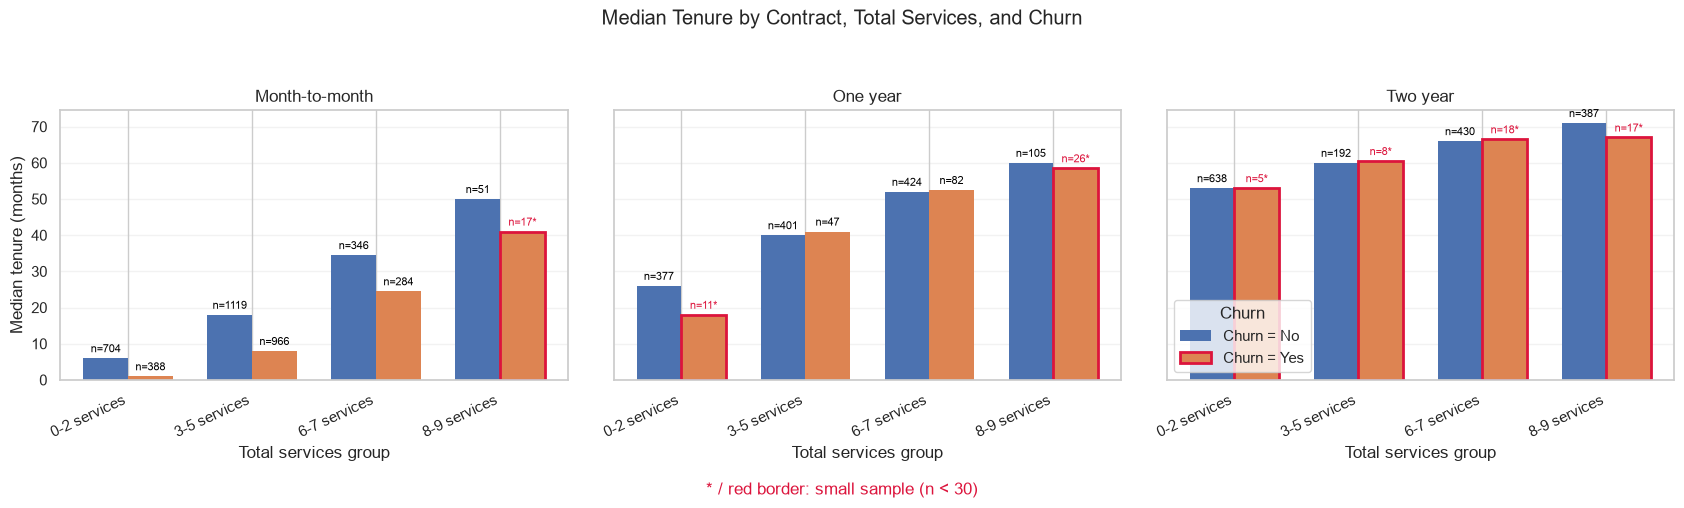

In [16]:
plot_data = churn_tenure_comparison.copy()
contracts = ["Month-to-month", "One year", "Two year"]
service_groups = ["0-2 services", "3-5 services", "6-7 services", "8-9 services"]
churn_order = ["No", "Yes"]

fig, axes = plt.subplots(1, len(contracts), figsize=(17, 5), sharey=True)
bar_width = 0.36
x = range(len(service_groups))

for axis, contract in zip(axes, contracts):
    contract_data = plot_data[plot_data["Contract"] == contract]
    for offset, churn in zip([-bar_width / 2, bar_width / 2], churn_order):
        values = (
            contract_data.set_index(["TotalServicesGroup", "Churn"])
            .reindex(pd.MultiIndex.from_product([service_groups, [churn]]))
        )
        heights = values["Median tenure (months)"].to_numpy()
        counts = values["Customer count"].to_numpy()
        small = values["Small sample"].fillna(False).to_numpy()
        bars = axis.bar(
            [position + offset for position in x],
            heights,
            width=bar_width,
            label=f"Churn = {churn}",
            edgecolor=["crimson" if is_small else "none" for is_small in small],
            linewidth=2,
        )
        for bar, count, is_small in zip(bars, counts, small):
            if pd.notna(bar.get_height()):
                axis.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 1,
                    f"n={int(count)}" + ("*" if is_small else ""),
                    ha="center",
                    va="bottom",
                    fontsize=8,
                    color="crimson" if is_small else "black",
                )
    axis.set_title(contract)
    axis.set_xticks(list(x), service_groups, rotation=25, ha="right")
    axis.set_xlabel("Total services group")
    axis.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Median tenure (months)")
axes[-1].legend(title="Churn")
fig.suptitle("Median Tenure by Contract, Total Services, and Churn")
fig.text(0.5, 0.01, "* / red border: small sample (n < 30)", ha="center", color="crimson")
plt.tight_layout(rect=[0, 0.04, 1, 0.93])
plt.show()


## MonthlyCharges by Contract, Total Services, and Churn

This section compares customer count, median MonthlyCharges, and mean MonthlyCharges for Churn = Yes and Churn = No.


In [17]:
monthly_charges_summary = (
    analysis_df.groupby(
        ["Contract", "TotalServicesGroup", "Churn"], observed=False
    )
    .agg(
        **{
            "Customer count": ("customerID", "size"),
            "Median MonthlyCharges": ("MonthlyCharges", "median"),
            "Mean MonthlyCharges": ("MonthlyCharges", "mean"),
        }
    )
    .reset_index()
)
monthly_charges_summary["Small sample"] = (
    monthly_charges_summary["Customer count"] < small_sample_threshold
)

print(f"Small-sample threshold: n < {small_sample_threshold}")
display(monthly_charges_summary)
print("Groups flagged as small samples:")
display(monthly_charges_summary[monthly_charges_summary["Small sample"]])


Small-sample threshold: n < 30


,Contract,TotalServicesGroup,Churn,Customer count,Median MonthlyCharges,Mean MonthlyCharges,Small sample
0,Month-to-month,0-2 services,No,704,20.700,31.145668,False
1,Month-to-month,0-2 services,Yes,388,44.400,44.179639,False
2,Month-to-month,3-5 services,No,1119,74.000,69.254379,False
3,Month-to-month,3-5 services,Yes,966,79.975,76.410921,False
4,Month-to-month,6-7 services,No,346,96.425,91.620954,False
5,Month-to-month,6-7 services,Yes,284,100.075,98.711092,False
6,Month-to-month,8-9 services,No,51,108.950,104.392157,False
7,Month-to-month,8-9 services,Yes,17,110.450,109.323529,True
8,One year,0-2 services,No,377,20.100,21.790716,False
9,One year,0-2 services,Yes,11,20.400,25.890909,True


Groups flagged as small samples:


,Contract,TotalServicesGroup,Churn,Customer count,Median MonthlyCharges,Mean MonthlyCharges,Small sample
7,Month-to-month,8-9 services,Yes,17,110.450,109.323529,True
9,One year,0-2 services,Yes,11,20.400,25.890909,True
15,One year,8-9 services,Yes,26,110.075,106.048077,True
17,Two year,0-2 services,Yes,5,24.500,22.700000,True
19,Two year,3-5 services,Yes,8,55.950,66.587500,True
21,Two year,6-7 services,Yes,18,97.275,93.883333,True
23,Two year,8-9 services,Yes,17,109.450,107.600000,True


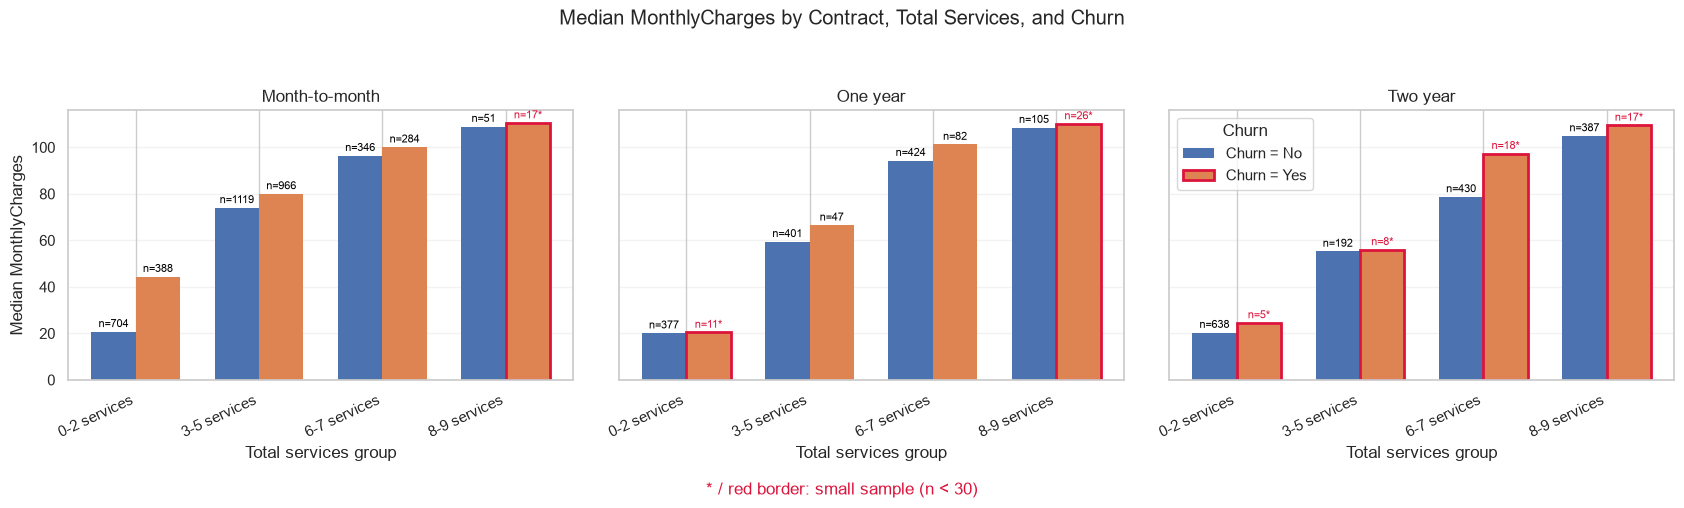

In [18]:
plot_data = monthly_charges_summary.copy()
contracts = ["Month-to-month", "One year", "Two year"]
service_groups = ["0-2 services", "3-5 services", "6-7 services", "8-9 services"]
churn_order = ["No", "Yes"]

fig, axes = plt.subplots(1, len(contracts), figsize=(17, 5), sharey=True)
bar_width = 0.36
x = range(len(service_groups))

for axis, contract in zip(axes, contracts):
    contract_data = plot_data[plot_data["Contract"] == contract]
    for offset, churn in zip([-bar_width / 2, bar_width / 2], churn_order):
        values = (
            contract_data.set_index(["TotalServicesGroup", "Churn"])
            .reindex(pd.MultiIndex.from_product([service_groups, [churn]]))
        )
        heights = values["Median MonthlyCharges"].to_numpy()
        counts = values["Customer count"].to_numpy()
        small = values["Small sample"].fillna(False).to_numpy()
        bars = axis.bar(
            [position + offset for position in x],
            heights,
            width=bar_width,
            label=f"Churn = {churn}",
            edgecolor=["crimson" if is_small else "none" for is_small in small],
            linewidth=2,
        )
        for bar, count, is_small in zip(bars, counts, small):
            if pd.notna(bar.get_height()):
                axis.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 1,
                    f"n={int(count)}" + ("*" if is_small else ""),
                    ha="center",
                    va="bottom",
                    fontsize=8,
                    color="crimson" if is_small else "black",
                )
    axis.set_title(contract)
    axis.set_xticks(list(x), service_groups, rotation=25, ha="right")
    axis.set_xlabel("Total services group")
    axis.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Median MonthlyCharges")
axes[-1].legend(title="Churn")
fig.suptitle("Median MonthlyCharges by Contract, Total Services, and Churn")
fig.text(0.5, 0.01, "* / red border: small sample (n < 30)", ha="center", color="crimson")
plt.tight_layout(rect=[0, 0.04, 1, 0.93])
plt.show()
